In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))
from src.data import SyntheticDataGenerator, QSARDataLoader
from src.experiments import ExperimentRunner
from src.plots import plot_learning_curves, plot_error_vs_surrogate, plot_decision_boundaries
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
generator = SyntheticDataGenerator(n_samples=600, random_state=42)
datasets = [generator.linearly_separable(), generator.nonseparable(flip_fraction=0.17)]

datasets.append(QSARDataLoader(ROOT / 'Data').load(download=True))



In [3]:
runner = ExperimentRunner(seed=42, test_size=.25, epochs=180)
results = {dataset.name: runner.run(dataset) for dataset in datasets}
summary = pd.concat([res.summary for res in results.values()], ignore_index=True)
display(summary.round(4))

print("Trained classifier classes:")
for loss_name, model in results["synthetic_separable"].models.items():
    print(f"  {loss_name}: {type(model).__name__}")


,dataset,loss,train_error,test_error,train_surrogate,test_surrogate,generalization_gap
0,synthetic_separable,hinge,0.0000,0.0000,0.0098,0.0152,0.0000
1,synthetic_separable,logistic,0.0000,0.0000,0.0725,0.0715,0.0000
2,synthetic_separable,squared,0.0000,0.0000,0.0892,0.0899,0.0000
3,synthetic_nonseparable,hinge,0.2600,0.2067,0.6231,0.4967,-0.0533
4,synthetic_nonseparable,logistic,0.2622,0.1933,0.5527,0.4810,-0.0689
5,synthetic_nonseparable,squared,0.2644,0.2000,0.3724,0.3104,-0.0644
6,qsar_biodegradation,hinge,0.1228,0.1336,0.3146,0.3302,0.0108
7,qsar_biodegradation,logistic,0.1253,0.1565,0.3101,0.3474,0.0312
8,qsar_biodegradation,squared,0.1380,0.1603,0.2255,0.2693,0.0223


Trained classifier classes:
  hinge: LinearSVM
  logistic: LogisticRegressionClassifier
  squared: LeastSquaresClassifier


synthetic_separable


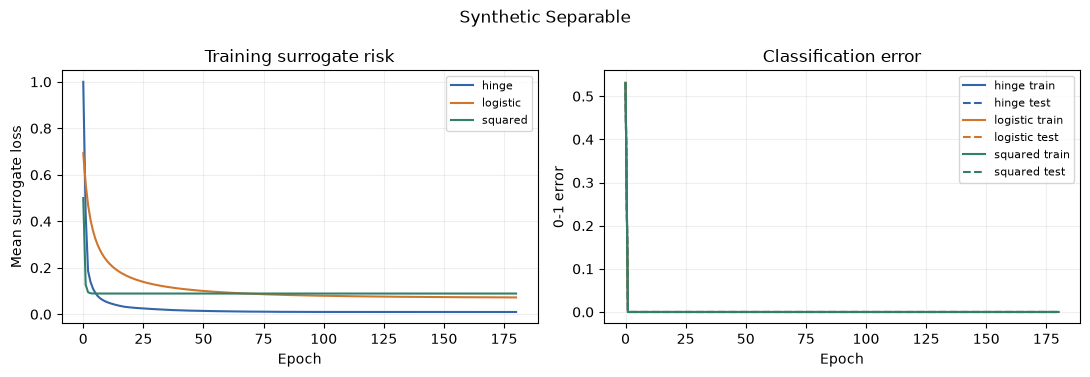

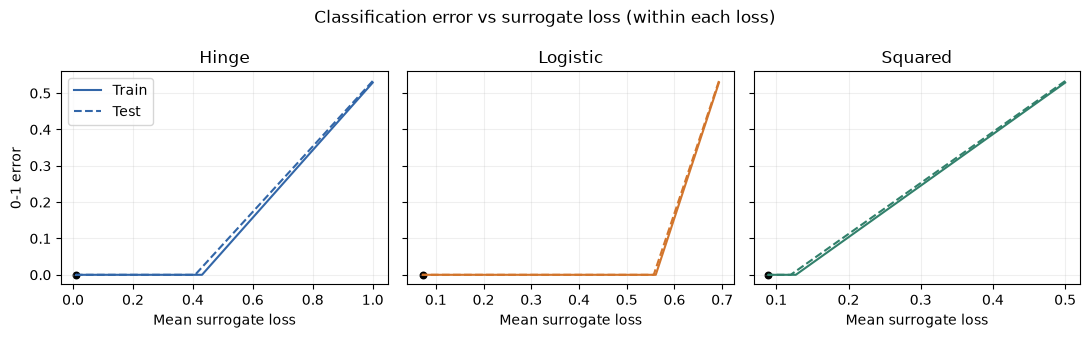

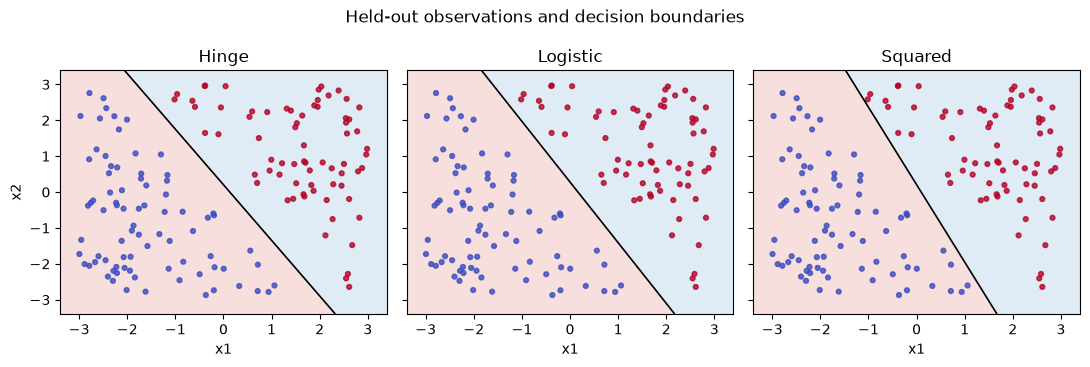

synthetic_nonseparable


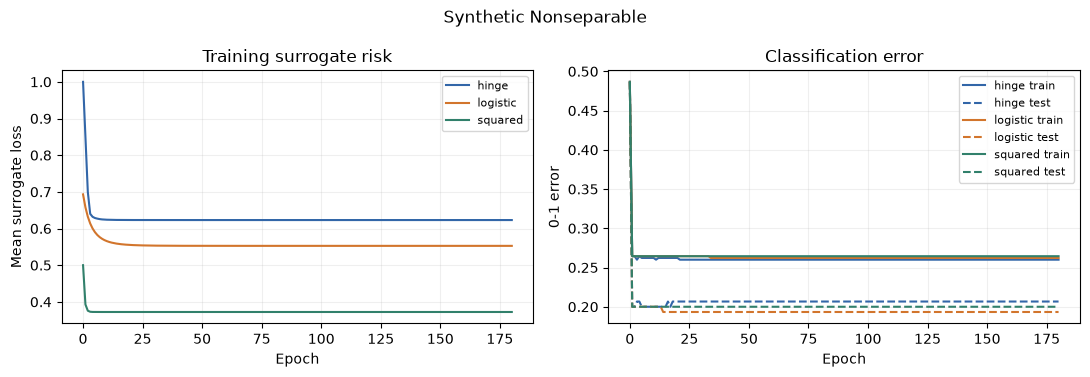

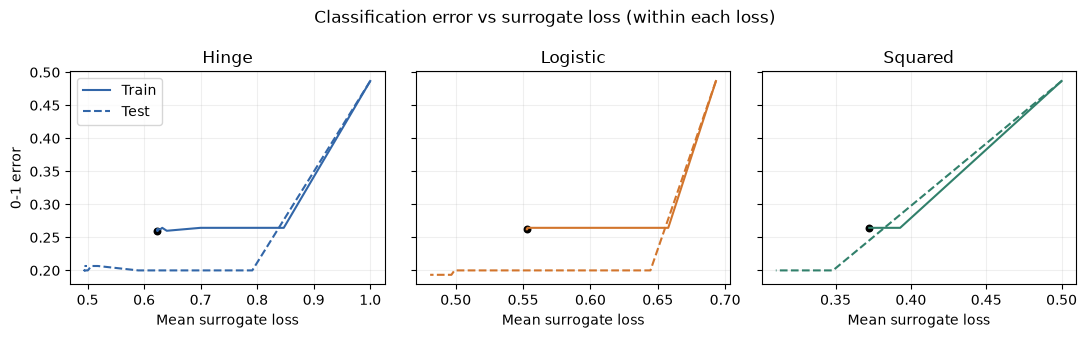

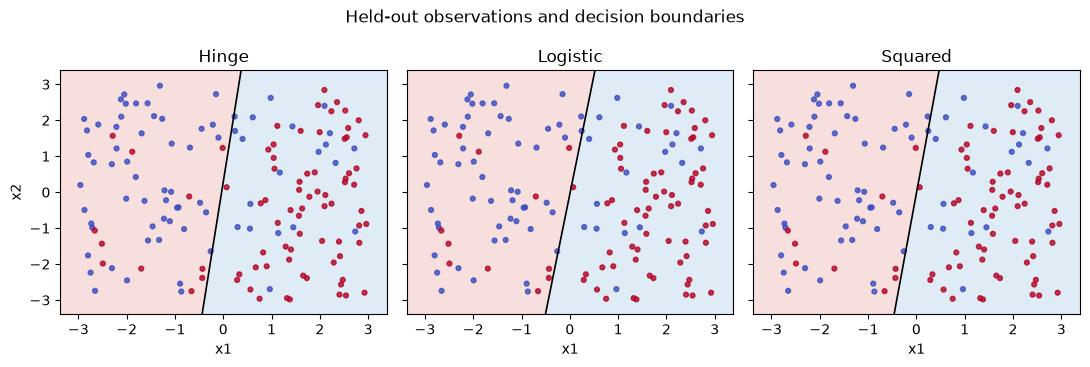

qsar_biodegradation


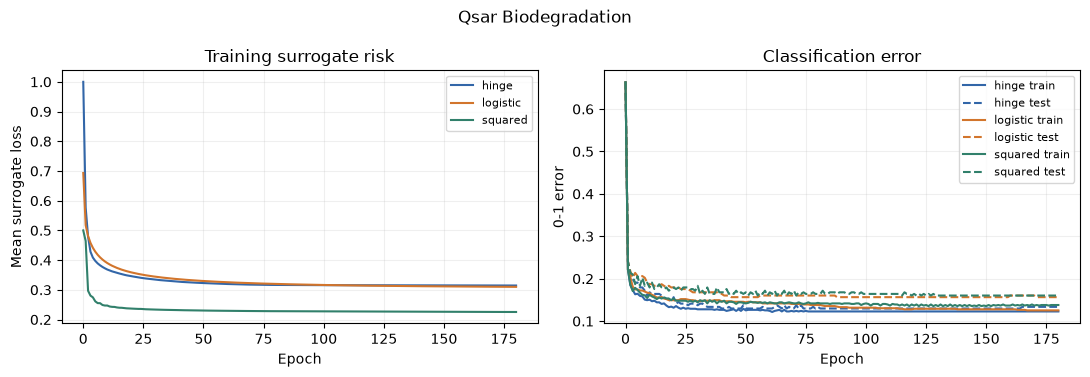

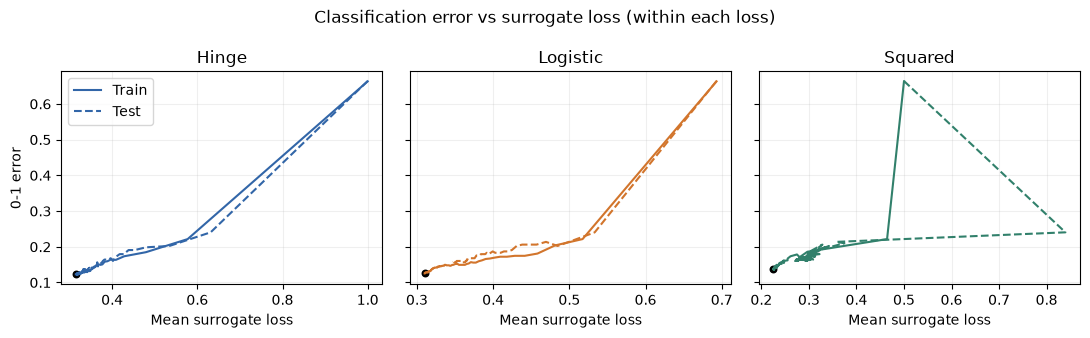

In [4]:
for name, result in results.items():
    print(name)
    plot_learning_curves(result)
    plt.show()
    plot_error_vs_surrogate(result)
    plt.show()
    if result.dataset.X.shape[1] == 2:
        plot_decision_boundaries(result)
        plt.show()
